# Partition uncertainties in projections of impacts

For different sets of runs: 
- a "balanced panel" of GCMs / runs
- all available runs at GWLX
- with one reanalysis left out

In [2]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import zarr
import copy
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar
from matplotlib import colors as mcolors

import distributed

from funcs_support import get_filepaths,get_params,utility_save
from funcs_readregs import coeffs_mortality, coeffs_gdppc
from funcs_processing import calc_uncerts
from funcs_plot import plot_map, vals_to_color_triangle

dir_list = get_params()

In [3]:
from distributed import Client

# Start dask client 
# (playing around with workers, threads for efficiency)
client = Client(n_workers=6,
    threads_per_worker=3,
    processes=True,
    memory_limit="8GB")
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 41911 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/41911/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/41911/status,Workers: 6
Total threads: 18,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:37825,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/41911/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:34785,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/33505/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:43469,


2026-04-28 14:33:35,631 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 90e27284da1a8785f0f3c7ae5d74c856 initialized by task ('rechunk-merge-rechunk-transfer-1199ef483b12f7880a30e19258cf4d4b', 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 15) executed on worker tcp://127.0.0.1:35269
2026-04-28 14:33:41,800 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 90e27284da1a8785f0f3c7ae5d74c856 deactivated due to stimulus 'task-finished-1777408421.7995489'


## Climate uncertainty partitioning

In [4]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':False},
               'mortality-interacted':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
              'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','popwght':True}}

#params_proc = {'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','popwght':True}}


In [5]:
overwrite = True
for res in ['1deg']:#['025deg','1deg']:
    for proc in ['payroll']:#params_proc:
        if res == '025deg':
            output_fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}.zarr'
        else:
            output_fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}_1deg.zarr'
        if overwrite or (not os.path.exists(output_fn)):
            #---------------------------
            # Setup
            #---------------------------
            # Load impacts projections
            if res == '025deg':
                fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*ALLGWL*.zarr'))
            elif res == '1deg':
                fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg-1deg_*ALLGWL*.zarr'))
            def load_impact(fn):
                ds_tmp = xr.open_zarr(fn,consolidated=False)
                ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
                ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
            
                ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
                if 'idv' in ds_tmp.coords:
                    ds_tmp = ds_tmp.reset_index('idv')
                ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
                return ds_tmp
            
            with warnings.catch_warnings():
                # Silence zarr warnings related to the /.done flags used
                warnings.filterwarnings('ignore')
                dss = xr.concat([load_impact(fn) for fn in fns],
                            dim='idv',join='outer')
            # For interacted, the signal is the difference between 
            # "dmortality" (assuming climate + society changing) and
            # "dmortality_ref" (assuming climate constant, society changing)
            if proc == 'mortality-interacted':
                dss['dmortality-interacted'] = dss['dmortality'] - dss['dmortality_ref']
                dss = dss.drop_vars(['dmortality','dmortality_ref'])
            
            dss = dss.chunk({'poly_idx':50,'idv':-1,'proj_base':-1,'gwl':-1})
    
            # Save temporary rechunked file to make dask graphing more stable
            tmp_fn = dir_list['proc']+'tmp/uncert_rechunk_cache_tmp.zarr'
            dss = dss.reset_index('idv')
            for v in dss.coords:
                dss[v] = dss[v].load()
            utility_save(dss.drop_encoding(),tmp_fn,zarr_mode = 'w')
            dss = xr.open_zarr(tmp_fn)
            for v in ['model','exprun','experiment','run']:
                # Explicitly cast these dims as objects because of a numpy bug
                dss[v] = dss[v].astype(object).load()
            dss = dss.set_index(idv = ['model','exprun']).drop_vars(['experiment','run'])
    
            # Figure out how many BCD-ME members reach a given GWL
            # (copy.deepcopy() necessary as a workaround around a numpy bug
            # affecting the unstack a few lines down that's triggered 
            # indirectly by the reset_index here)
            gwl_counter = copy.deepcopy(dss.maxgwl).load().reset_index('idv').groupby(['model','maxgwl']).count()
            gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
            #print(gwl_counter)
            
            uncerts_all = []
            #---------------------------
            # Uncertainty partitioning over all runs
            # (for all LEs, defined as >= 5 runs)
            #---------------------------
            nruns = 5
    
            gwlmods = gwl_counter.sel(maxgwl=1.5)
            proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
            
            dss_tmp = dss.isel(idv=[m in proc_mods for m in dss.model.values]).chunk({'idv':-1})
            dss_tmp = dss_tmp.unstack('idv')['d'+proc]
            dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
            
            # Calculate uncertainty partitioning
            with warnings.catch_warnings():
                # Ignoring chunk increase warnings and divide by 0s in uncertainty 
                # partitioning (happens over ocean, e.g.)
                warnings.filterwarnings('ignore')
                uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()

            uncerts['numruns'] = (~np.isnan(dss_tmp.mean('poly_idx'))).sum('exprun').load()
            uncerts = uncerts.expand_dims({'sample':['allruns']})
            
            uncerts_all.append(uncerts)
            
            #---------------------------
            # Uncertainty partitioning over a balanced panel up to GWL 3
            #---------------------------
            max_gwl = 3
            if proc == 'payroll':
                nruns = 10
            else:
                nruns = 13
            
            gwlmods = gwl_counter.sel(maxgwl=3)
            proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
            
            dss_tmp = dss.isel(idv = dss.maxgwl.load()>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
            dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
            dss_tmp = dss_tmp.unstack('idv')['d'+proc]
            dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
            
            with warnings.catch_warnings():
                # Ignoring chunk increase warnings and divide by 0s in uncertainty 
                # partitioning (happens over ocean, e.g.)
                warnings.filterwarnings('ignore')
                uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()

            uncerts['numruns'] = (~np.isnan(dss_tmp.mean('poly_idx'))).sum('exprun').load()
            uncerts = uncerts.expand_dims({'sample':[f'{str(nruns)}runs{str(dss_tmp.sizes['model'])}mods']})
            
            uncerts_all.append(uncerts)
    
            #---------------------------
            # Uncertainty partitioning over a balanced panel up to GWL 3
            # withholding a reanalysis each time
            #---------------------------
            for proj_base in dss.proj_base.values:
                max_gwl = 3
                if proc == 'payroll':
                    nruns = 10
                else:
                    nruns = 13
                
                gwlmods = gwl_counter.sel(maxgwl=3)
                proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
                
                dss_tmp = dss.isel(idv = dss.maxgwl.load()>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
                dss_tmp = dss_tmp.sel(proj_base = [pb for pb in dss_tmp.proj_base.values if pb != proj_base])
                dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
                dss_tmp = dss_tmp.unstack('idv')['d'+proc]
                dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
                
                with warnings.catch_warnings():
                    # Ignoring chunk increase warnings and divide by 0s in uncertainty 
                    # partitioning (happens over ocean, e.g.)
                    warnings.filterwarnings('ignore')
                    uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()

                uncerts['numruns'] = (~np.isnan(dss_tmp.mean('poly_idx'))).sum('exprun').load()
                uncerts = uncerts.expand_dims({'sample':[f'{str(nruns)}runs{str(dss_tmp.sizes['model'])}mods_no{proj_base}']})
                
                uncerts_all.append(uncerts)
            
            #---------------------------
            # Export
            #---------------------------
            # Concatenate into single ds
            uncerts_all = xr.concat(uncerts_all,dim='sample')
            uncerts_all = uncerts_all.set_coords('numruns')
            uncerts_all = uncerts_all.where(uncerts_all.sum('typ')>0)
            
            # Export
            uncerts_all.attrs = {'SOURCE':'4_partition_uncertainty.ipynb',
                                 'DESCRIPTION':f'Uncertainty partitioning of projections of {proc} between model, internal, and reanalysis sources'}

            with warnings.catch_warnings():
                # Ignoring chunk increase warnings and divide by 0s in uncertainty 
                # partitioning (happens over ocean, e.g.)
                warnings.filterwarnings('ignore')
                utility_save(uncerts_all,output_fn,zarr_mode = 'w')
    
            os.system('rm -rf '+tmp_fn)
            print('Temporary file '+tmp_fn+' removed.')
        else:
            print(output_fn+' exists!')
    


/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=6, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=15, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change wit

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xarray/core/nputils.py:

/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_payroll_1deg.zarr removed to allow overwrite!
/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_payroll_1deg.zarr saved!
Temporary file /glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr removed.


In [64]:
dsss = dict()
for res in ['025deg','1deg']:
    # Load impacts projections
    if res == '025deg':
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*ALLGWL*.zarr'))
    elif res == '1deg':
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg-1deg_*ALLGWL*.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dsss[res] = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')

In [72]:
zeronums = {res:dsss[res].sel(obstreat='sep',weighting='pop',timeframe='1986-2008',resolution=res).isel(gwl=slice(1,None)).dpayroll == 0
            for res in dsss}

In [75]:
zeronums_byloc = {res:zeronums[res].sum('idv').load()
      for res in zeronums}

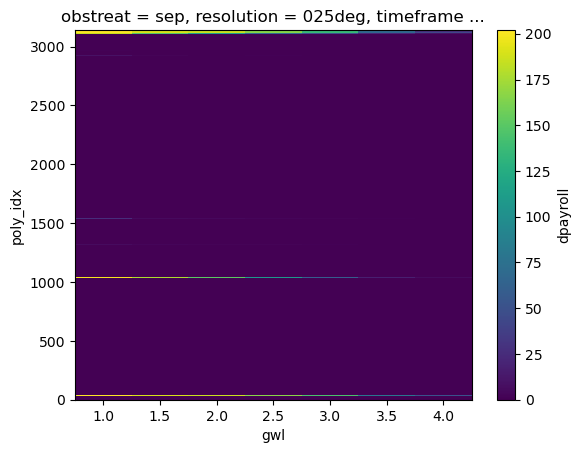

In [79]:
zeronums_byloc['025deg'].sel(proj_base='ERA5').plot()

In [103]:
np.unique(dss.model)

array(['ACCESS-CM2', 'ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1',
       'CAMS-CSM1-0', 'CMCC-ESM2', 'CNRM-CM6-1', 'CNRM-ESM2-1', 'CanESM5',
       'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-g3', 'IPSL-CM6A-LR',
       'MIROC-ES2L', 'MIROC6', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR',
       'MRI-ESM2-0', 'NESM3'], dtype='<U15')

In [101]:
gdf = gpd.read_file('../aux_data/geo_data/UScounties.shp')

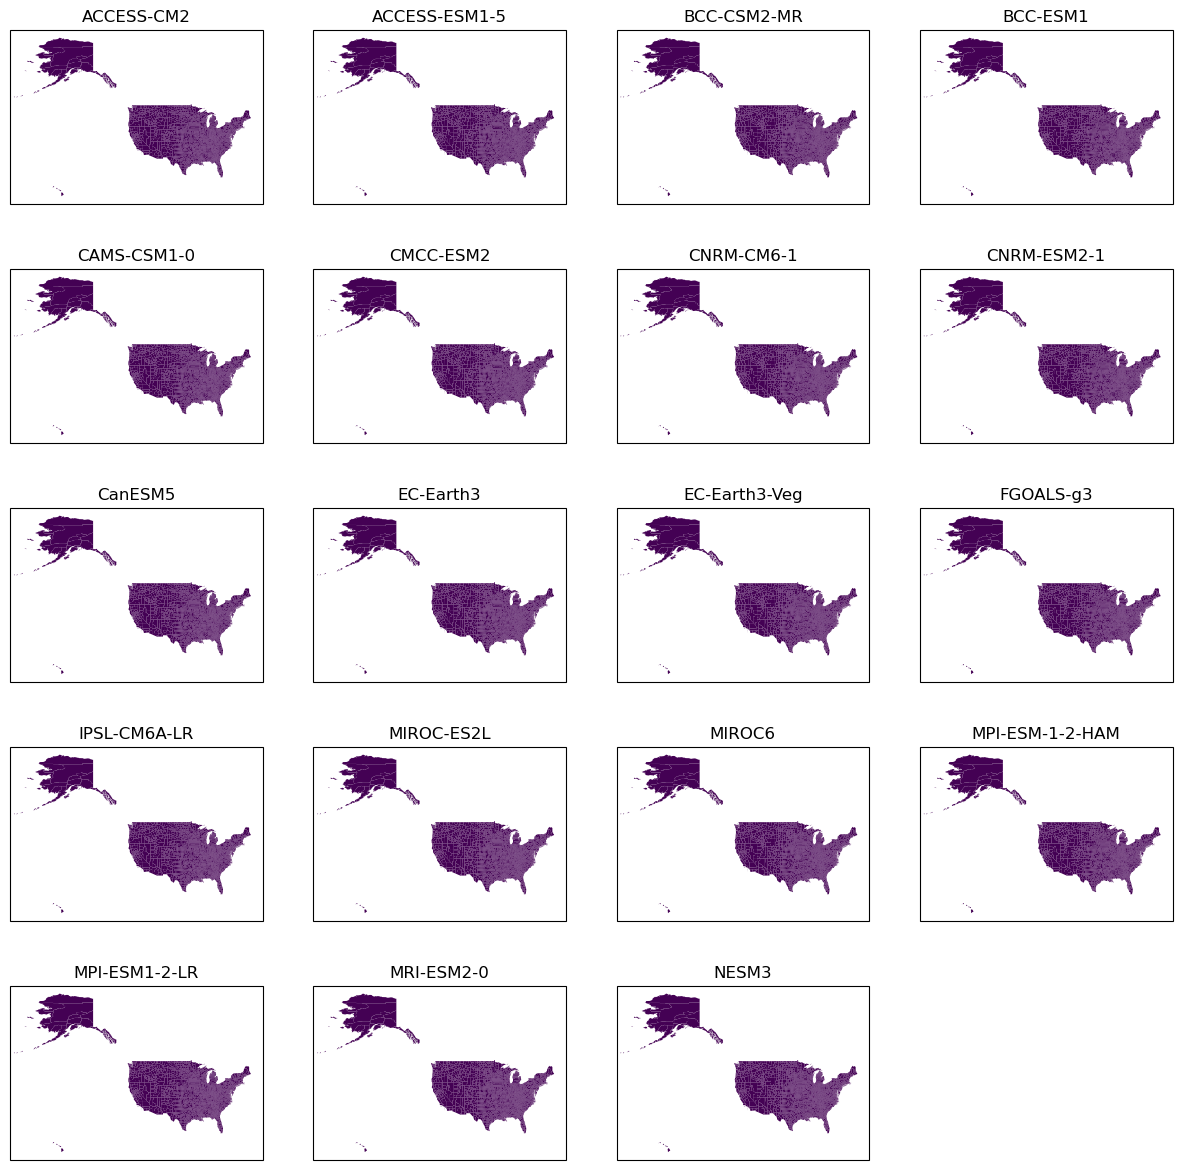

In [107]:
from matplotlib import pyplot as plt
from cartopy import crs as ccrs
base_fn = '/glade/derecho/scratch/schwarzwald/impact_uncertainty/aggs/'
fig = plt.figure(figsize=(15,15))
for mod_idx,mod in enumerate(np.unique(dss.model)):
    ax = plt.subplot(5,4,mod_idx+1,projection=ccrs.PlateCarree())
    d = xr.open_dataset(base_fn+'days90plus_agg-1deg_ACCESS-ESM1-5_ALLRUNS_ALLGWLs_adm2-us_popwght.zarr').days90plus.isel(binF=0).sel(gwl=2).min(['idv','proj_base'])
    plot_map(d,gdf,ax=ax,fig=fig)
    ax.set_title(mod)

.............

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_99880/1809004121.py:8: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  d = xr.open_zarr(f'{base_fn}bcd_me_qdm_{mod}.zarr')
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at .done_v021 is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at .d

......

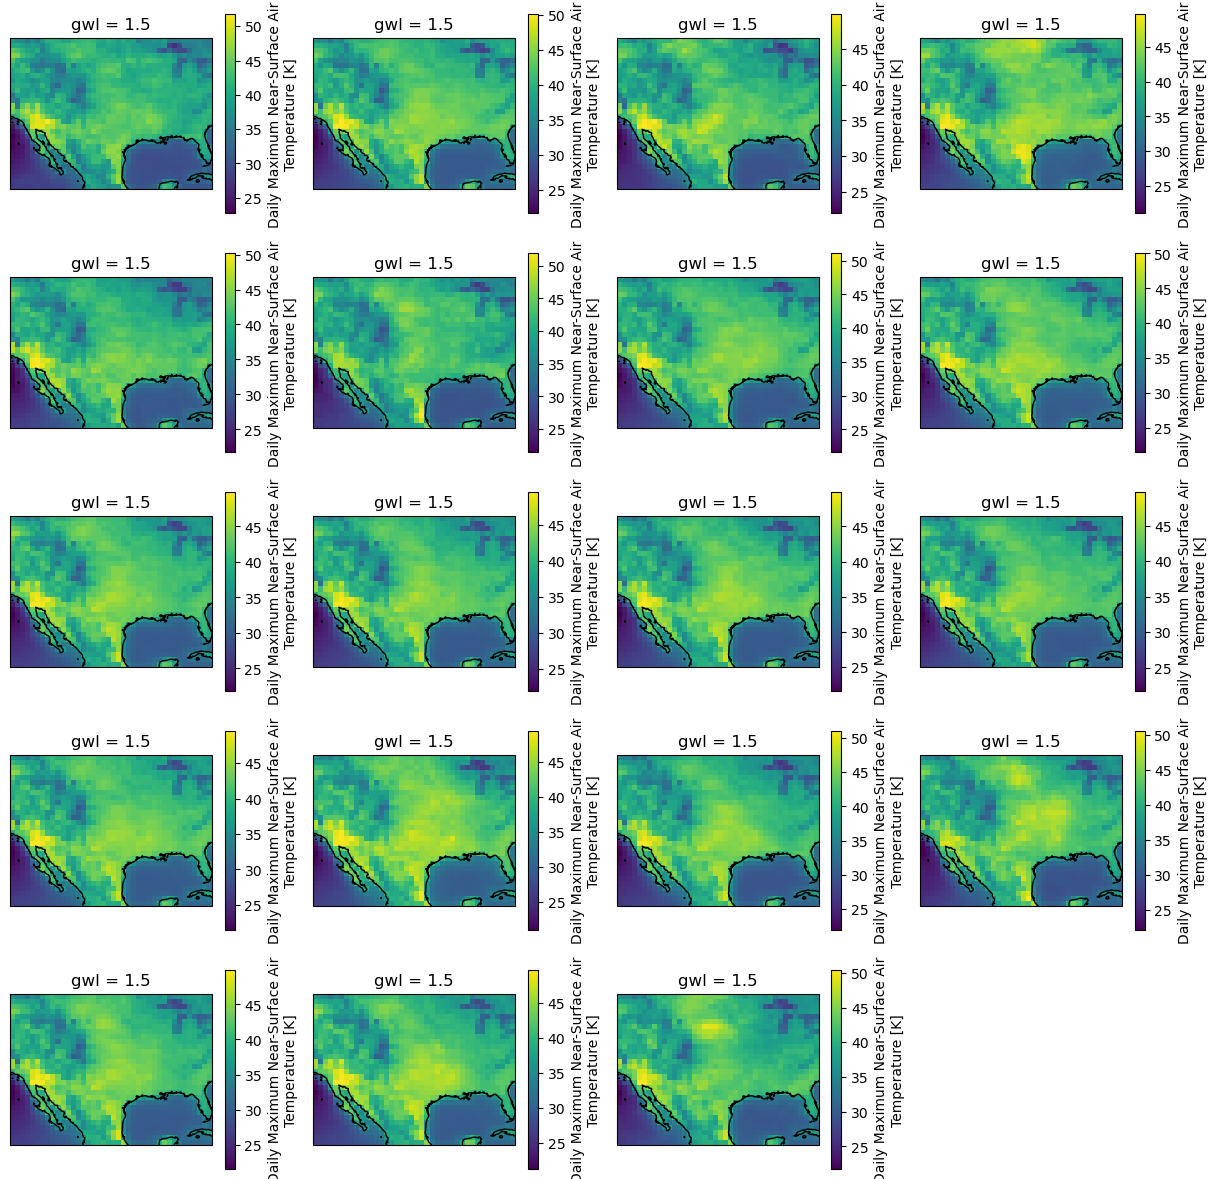

In [115]:
from matplotlib import pyplot as plt
from cartopy import crs as ccrs
base_fn = f'/glade/campaign/cgd/cas/schwarzwald/bcd_me/'
fig = plt.figure(figsize=(15,15))
for mod_idx,mod in enumerate(np.unique(dss.model)):
    print('.',end='')
    ax = plt.subplot(5,4,mod_idx+1,projection=ccrs.PlateCarree())
    d = xr.open_zarr(f'{base_fn}bcd_me_qdm_{mod}.zarr')
    (d.tasmax.sel(gwl=1.5,lat=slice(20,50),lon=slice(-120,-80)).max(('dayofyear','year')).mean(('proj_base','idv'))-273.15).plot(transform=ccrs.PlateCarree())
    ax.coastlines()

In [113]:
d

<xarray.Dataset> Size: 72GB
Dimensions:        (proj_base: 4, lat: 142, lon: 360, gwl: 3, dayofyear: 365,
                    year: 20, idv: 1, variable: 2)
Coordinates:
  * proj_base      (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
  * lat            (lat) float64 1kB -55.5 -54.5 -53.5 -52.5 ... 83.5 84.5 85.5
  * lon            (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
  * gwl            (gwl) float64 24B 0.61 1.0 1.5
  * dayofyear      (dayofyear) int64 3kB 1 2 3 4 5 6 ... 360 361 362 363 364 365
  * year           (year) int64 160B 1 2 3 4 5 6 7 8 ... 13 14 15 16 17 18 19 20
    calendar_year  (idv, gwl, year) float64 480B dask.array<chunksize=(1, 3, 20), meta=np.ndarray>
    experiment     (idv) object 8B dask.array<chunksize=(1,), meta=np.ndarray>
    has_data       (variable, gwl, idv) bool 6B dask.array<chunksize=(2, 3, 1), meta=np.ndarray>
    model          (idv) <U8 32B dask.array<chunksize=(1,), meta=np.ndarray>
    run            (idv) object 8B dask.array<chunksize=(1,), meta=np.ndarray>
  * variable       (variable) object 16B 'tas' 'tasmax'
Dimensions without coordinates: idv
Data variables:
    tas            (proj_base, lat, lon, gwl, dayofyear, year, idv) float64 36GB dask.array<chunksize=(1, 40, 40, 1, 365, 20, 1), meta=np.ndarray>
    tasmax         (proj_base, lat, lon, gwl, dayofyear, year, idv) float64 36GB dask.array<chunksize=(1, 40, 40, 1, 365, 20, 1), meta=np.ndarray>
Attributes:
    DESCRIPTION:  BCC-ESM1 ScenarioMIP runs, bias-corrected using Quantile De...
    Project:      Bias-Corrected, Downscaled Massive Ensemble (BCD-ME)
    Creators:     Kevin Schwarzwald, Nathan Lenssen, Radley Horton, and Gerno...
    Version:      v0.2.1
    License:      CC BY 4.0

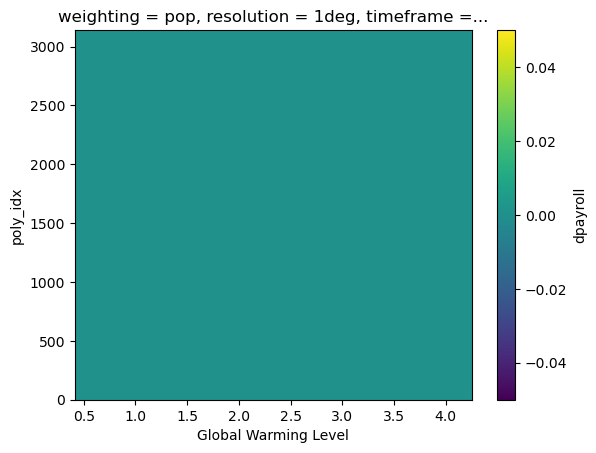

In [88]:
sp = {'proj_base':'ERA5','resolution':'1deg','timeframe':'1986-2008','obstreat':'sep','weighting':'pop'}
dsss['1deg'].sel(sp).isel(idv=100).dpayroll.plot()

In [81]:
np.unique(zeronums_byloc['1deg'].sel(proj_base='ERA5'),return_counts=True)

(array([146, 147, 148, 149, 150, 151, 153, 154, 157, 158, 160, 161, 162,
        165, 169, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185,
        186, 187, 188, 189, 193, 195, 196, 197, 198, 199, 200, 201, 202,
        203, 204, 207, 209, 211, 212, 213, 214, 215, 216, 217, 218, 219,
        220, 221, 223, 224, 225, 226, 227, 229, 230, 231, 232, 233, 234,
        235, 236, 237, 238, 239, 240, 241, 243, 244, 245, 247, 249, 250,
        251, 254, 255, 257, 258, 261, 262, 263, 266, 267, 268, 270, 271,
        273, 274, 275, 278, 279, 283, 284, 285, 286, 287, 288, 289, 290,
        292, 293, 294, 295, 296, 297, 299, 301, 302, 303, 305, 307, 311,
        313, 314, 316, 317, 320, 321, 323, 328, 329, 330, 331, 333, 334,
        336, 337, 339, 341, 343, 346, 347, 348, 349, 350, 351, 352, 353,
        354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366,
        368, 369, 370, 371, 372, 373, 374, 375]),
 array([ 3054,  3021,    34,     5,     2,     4,     1,     5,     4,
   

(array([8.04000000e+02, 2.03220000e+04, 1.21008000e+06, 2.01438690e+07,
        2.46013674e+08, 1.00467970e+07, 2.17131900e+06, 5.38330000e+05,
        6.89530000e+04, 1.33080000e+04]),
 array([-0.08813226, -0.06948953, -0.0508468 , -0.03220408, -0.01356135,
         0.00508138,  0.02372411,  0.04236684,  0.06100956,  0.07965229,
         0.09829502]),
 <BarContainer object of 10 artists>)

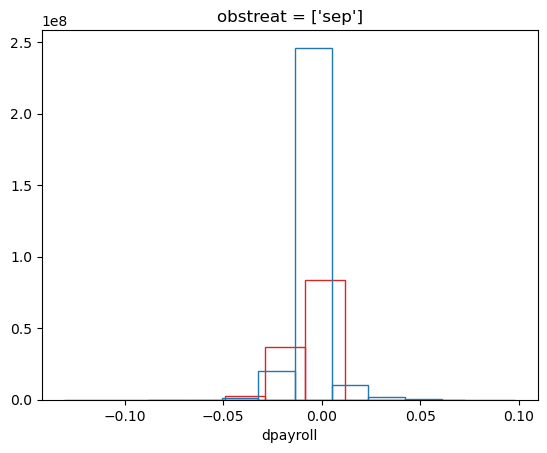

In [65]:
dsss['025deg'].dpayroll.plot.hist(facecolor='none',edgecolor='tab:red')
dsss['1deg'].dpayroll.plot.hist(facecolor='none',edgecolor='tab:blue')

In [13]:
gwl_counter

<xarray.DataArray 'maxgwl' (model: 24, maxgwl: 7)> Size: 1kB
array([[ 0.,  1.,  1.,  1.,  1.,  1.,  1.],
       [ 5.,  5.,  5., 24., 24., 24., 24.],
       [ 0.,  1.,  2.,  2.,  2.,  2.,  2.],
       [ 0.,  0.,  0.,  0.,  0.,  1.,  1.],
       [ 0.,  0.,  0.,  1.,  2.,  2.,  2.],
       [ 3.,  4.,  7.,  7.,  8.,  8.,  8.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.],
       [ 6., 12., 15., 18., 18., 18., 18.],
       [ 5.,  7., 13., 26., 31., 41., 41.],
       [79., 86., 86., 86., 86., 86., 86.],
       [10., 15., 32., 35., 35., 35., 35.],
       [ 6.,  9., 13., 13., 13., 13., 13.],
       [ 0.,  0.,  3.,  7., 10., 10., 10.],
       [ 0.,  0.,  1.,  1.,  1.,  1.,  1.],
       [17., 18., 28., 28., 28., 28., 28.],
       [ 0.,  0.,  1.,  1.,  1.,  1.,  1.],
       [ 0.,  0., 28., 31., 34., 34., 60.],
       [ 0.,  0.,  0.,  0.,  0.,  1.,  1.],
       [ 0.,  6., 16., 20., 30., 30., 30.],
       [ 0.,  2.,  7.,  8.,  8.,  8., 12.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.],
       [ 0.,  0.,  1.,  1.,  1.,  1.,  1.],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.]])
Coordinates:
  * model    (model) object 192B 'ACCESS-CM2' 'ACCESS-ESM1-5' ... 'TaiESM1'
  * maxgwl   (maxgwl) float64 56B 4.0 3.5 3.0 2.5 2.0 1.5 1.0